# CylinderFlow assignment: deterministic prediction vs conditional flow matching

In this assignment you will model the future velocity field of a two-dimensional flow around a cylinder on an **unstructured, nonuniform triangular mesh**.

You will build two predictors using the **same supplied data**:

1. a **deterministic predictor** trained as a point predictor; and
2. a **conditional flow-matching predictor** that represents a distribution of possible future velocity fields.

The neural-network architecture is **not prescribed**. Your model should be able to use the information supplied by the mesh and the current flow state.

This notebook provides the problem specification, data loading, dataset class, data inspection, and the final evaluation code. Model architecture, optimization, training, and the numerical details of flow-matching sampling are your task.


## 1. What is in the dataset?

The cylinder-flow dataset is based on the MeshGraphNets benchmark introduced by Pfaff et al. in [*Learning Mesh-Based Simulation with Graph Networks*](https://arxiv.org/abs/2010.03409) (ICLR 2021). The data consist of multiple independent **trajectories** of two-dimensional flow around a cylinder.

The assignment file is intended to contain:

- **500 training trajectories**;
- **20 validation trajectories**;
- **20 held-out test trajectories**.

Each trajectory contains:

- **600 time states** separated by $\Delta t=0.01\,\mathrm{s}$, corresponding to times $0,0.01,\ldots,5.99\,\mathrm{s}$;
- one **static 2D triangular mesh** that is reused for all 600 states in that trajectory;
- a 2D velocity vector $(u_x,u_y)$ at every mesh node and every time state;
- a node-type label describing whether a node is an interior node, inflow node, outflow node, or wall boundary node.

### Important mesh properties

The mesh is **unstructured and spatially nonuniform**. It is not a Cartesian image grid, so the velocity field should not be reshaped into a rectangular image.

The number of nodes is **not identical across trajectories**. In the supplied training data, trajectories have roughly 600 nodes on average (the current training set spans approximately 552--898 nodes). Triangle connectivity also varies across trajectories.

Within a single trajectory, however, the mesh is fixed in time: only the velocity field changes.

The loading cells below verify the exact split sizes and mesh statistics stored in your copy of the data file.


### Array structure for one trajectory

For a trajectory with \(T\) time states, \(N\) mesh nodes, and \(M\) triangles:

| key | shape | meaning |
|---|---:|---|
| `mesh_pos` | `(N, 2)` | node coordinates $(x,y)$ |
| `cells` | `(M, 3)` | the three node indices of every triangular cell |
| `node_type` | `(N,)` | integer boundary/interior label for each node |
| `velocity` | `(T, N, 2)` | velocity components $(u_x,u_y)$ |

The node labels used in this assignment are:

- `0`: interior / normal node
- `4`: inflow node
- `5`: outflow node
- `6`: wall boundary node

The **dynamic nodes** for the prediction loss are interior and outflow nodes (`0` and `5`).

In the supplied dataset, inflow (`4`) and wall (`6`) velocities are prescribed boundary values and are constant in time. They therefore do not need to be learned as evolving state variables. During autoregressive rollout, restore these known boundary values after every prediction step.


In [3]:
%pip -q install h5py tqdm

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.0.1 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


In [1]:
from pathlib import Path
import math
import random

import h5py
import numpy as np
import pandas as pd
import torch
from torch.utils.data import Dataset, DataLoader
import matplotlib.pyplot as plt
from tqdm.auto import tqdm

SEED = 7
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", DEVICE)

Device: cuda


In [2]:
import torch, platform
print(torch.cuda.get_device_name(0))
print(round(torch.cuda.get_device_properties(0).total_memory / 1e9, 1), "GB GPU memory")
print(platform.processor())

NVIDIA GeForce RTX 4060 Laptop GPU
8.6 GB GPU memory
AMD64 Family 25 Model 116 Stepping 1, AuthenticAMD


## 2. Download and load the supplied data file

The code below will download and place the supplied HDF5 file next to this notebook.

The HDF5 file is organized as

```text
/train/traj_0000/...
/train/traj_0001/...
/valid/traj_0000/...
/test/traj_0000/...
```

Each trajectory group contains the four arrays described above.

In [2]:
# ============================================================
# Download dataset
# ============================================================
DATA_PATH = Path("cylinderflow_assignment.h5")

if not DATA_PATH.exists():
    !pip -q install gdown

    import gdown

    DATA_URL = (
        "https://drive.google.com/file/d/1Gqz9b4hfoDaOYvupbHlf1pl_48AP-oZ4/view?usp=sharing"
    )

    print("Downloading dataset...")

    gdown.download(
        url=DATA_URL,
        output=str(DATA_PATH),
        quiet=False,
    )

    print(
        "Download complete:",
        DATA_PATH,
    )

else:
    print(
        "Dataset already available:",
        DATA_PATH,
    )

Dataset already available: cylinderflow_assignment.h5


In [3]:
DATA_PATH = Path("cylinderflow_assignment.h5")

if not DATA_PATH.exists():
    raise FileNotFoundError(
        f"Could not find {DATA_PATH}. Change DATA_PATH to the supplied dataset file."
    )

with h5py.File(DATA_PATH, "r") as f:
    DT = float(f.attrs["dt"])
    HORIZON_STEPS = int(f.attrs["prediction_horizon_steps"])
    PREDICTION_DT = float(f.attrs["prediction_horizon_seconds"])

    print("Dataset:", f.attrs.get("dataset_name", "CylinderFlow"))
    print(f"Stored time step: {DT:.3f} s")
    print(f"Prediction horizon: {HORIZON_STEPS} states = {PREDICTION_DT:.1f} s")

    for split in ["train", "valid", "test"]:
        ids = sorted(f[split].keys())
        node_counts = np.array([f[split][tid]["mesh_pos"].shape[0] for tid in ids])
        tri_counts = np.array([f[split][tid]["cells"].shape[0] for tid in ids])
        n_states = np.array([f[split][tid]["velocity"].shape[0] for tid in ids])

        print(f"\n{split.upper()}")
        print("  trajectories:", len(ids))
        print("  states/trajectory:", sorted(set(n_states.tolist())))
        print(
            "  nodes: min / mean / max =",
            int(node_counts.min()),
            f"{node_counts.mean():.1f}",
            int(node_counts.max()),
        )

Dataset: CylinderFlow assignment dataset
Stored time step: 0.010 s
Prediction horizon: 100 states = 1.0 s

TRAIN
  trajectories: 500
  states/trajectory: [600]
  nodes: min / mean / max = 552 601.1 898

VALID
  trajectories: 20
  states/trajectory: [600]
  nodes: min / mean / max = 561 593.0 633

TEST
  trajectories: 20
  states/trajectory: [600]
  nodes: min / mean / max = 565 586.2 633


### Trajectories versus training pairs

The learning task uses a **direct 1-second prediction horizon**. Since the stored time spacing is $0.01\,\mathrm{s}$, the target for state index $t$ is state index $t+100$.

Let $x_t$ denote the **full flow state at physical time $t$ seconds**. The training pairs are sliding 1-second pairs such as

$
(x_{0.00},x_{1.00}),\quad
(x_{0.01},x_{1.01}),\quad
(x_{0.02},x_{1.02}),\quad \ldots
$

and later in the same trajectory,

$
(x_{1.00},x_{2.00}),\quad
(x_{1.05},x_{2.05}),\quad \ldots,\quad
(x_{4.99},x_{5.99}).
$

The important point is:

> **1 second is the separation between the input and target, not the spacing between consecutive training examples.**

A trajectory with 600 stored states provides

$
600-100=500
$

possible 1-second input/target pairs. Thus 500 training trajectories correspond to $250{,}000$ possible pairs, but they still come from only 500 independent trajectories.


## 3. Dataset class

The class below returns raw physical quantities and makes no assumption about your model architecture.

Because different trajectories can have different numbers of nodes, a conventional tensor batch cannot in general stack examples from different meshes. The provided `variable_mesh_collate` therefore returns a Python list when `batch_size > 1`. You may process samples individually, group compatible samples yourself, or implement another batching strategy.


In [4]:
NORMAL = 0
INFLOW = 4
OUTFLOW = 5
WALL_BOUNDARY = 6


def dynamic_node_mask(node_type):
    """Nodes whose velocity is predicted/evaluated dynamically."""
    return (node_type == NORMAL) | (node_type == OUTFLOW)


class CylinderFlowPairDataset(Dataset):
    """
    Direct-horizon input/target pairs from a variable-size triangular-mesh dataset.

    One item contains the static mesh plus
        velocity_t       = u(t)
        velocity_target  = u(t + 1 s)
        delta_velocity   = velocity_target - velocity_t
    """

    def __init__(self, h5_path, split="train"):
        self.h5_path = str(h5_path)
        self.split = split
        self._h5 = None
        self._static_cache = {}

        with h5py.File(self.h5_path, "r") as f:
            if split not in f:
                raise KeyError(f"Unknown split {split!r}")

            self.dt = float(f.attrs["dt"])
            self.horizon_steps = int(f.attrs["prediction_horizon_steps"])
            self.prediction_dt = float(f.attrs["prediction_horizon_seconds"])
            self.traj_ids = sorted(f[split].keys())

            self.index = []
            for traj_id in self.traj_ids:
                T = int(f[split][traj_id]["velocity"].shape[0])
                n_valid = T - self.horizon_steps
                self.index.extend((traj_id, t) for t in range(n_valid))

    def _file(self):
        # Each DataLoader worker gets its own lazily opened handle.
        if self._h5 is None:
            self._h5 = h5py.File(self.h5_path, "r")
        return self._h5

    def __getstate__(self):
        state = self.__dict__.copy()
        state["_h5"] = None
        state["_static_cache"] = {}
        return state

    def __len__(self):
        return len(self.index)

    def _static(self, traj_id):
        if traj_id not in self._static_cache:
            g = self._file()[self.split][traj_id]
            self._static_cache[traj_id] = {
                "mesh_pos": torch.from_numpy(g["mesh_pos"][:]).float(),
                "cells": torch.from_numpy(g["cells"][:].astype(np.int64)).long(),
                "node_type": torch.from_numpy(g["node_type"][:].astype(np.int64)).long(),
            }
        return self._static_cache[traj_id]

    def __getitem__(self, idx):
        traj_id, t = self.index[idx]
        g = self._file()[self.split][traj_id]
        static = self._static(traj_id)

        u0 = torch.from_numpy(g["velocity"][t]).float()
        u1 = torch.from_numpy(g["velocity"][t + self.horizon_steps]).float()

        return {
            "trajectory_id": traj_id,
            "time_index": t,
            "time_s": t * self.dt,
            "target_time_index": t + self.horizon_steps,
            "target_time_s": (t + self.horizon_steps) * self.dt,
            "mesh_pos": static["mesh_pos"],
            "cells": static["cells"],
            "node_type": static["node_type"],
            "dynamic_mask": dynamic_node_mask(static["node_type"]),
            "velocity_t": u0,
            "velocity_target": u1,
            "delta_velocity": u1 - u0,
        }

    def close(self):
        if self._h5 is not None:
            self._h5.close()
            self._h5 = None


def variable_mesh_collate(batch):
    # Mesh sizes vary, so do not torch.stack different trajectories automatically.
    return batch


train_dataset = CylinderFlowPairDataset(DATA_PATH, "train")
valid_dataset = CylinderFlowPairDataset(DATA_PATH, "valid")
test_dataset = CylinderFlowPairDataset(DATA_PATH, "test")

print("Training pairs:", len(train_dataset))
print("Validation pairs:", len(valid_dataset))
print("Test pairs:", len(test_dataset))

Training pairs: 250000
Validation pairs: 10000
Test pairs: 10000


### Concrete examples of the 1-second pairs

The following cell prints several pairs from the first training trajectory. It is included to make the sliding horizon explicit. For example, a pair beginning at $1.05\,\mathrm{s}$ has its target at $2.05\,\mathrm{s}$, not at the next stored state $1.06\,\mathrm{s}$.


In [5]:
# Show several explicit pairs from the first training trajectory.
first_traj_id = train_dataset.traj_ids[0]

example_start_steps = [
    0,      # 0.00 -> 1.00 s
    1,      # 0.01 -> 1.01 s
    100,    # 1.00 -> 2.00 s
    105,    # 1.05 -> 2.05 s
    499,    # 4.99 -> 5.99 s
]

print("Examples from", first_traj_id)

for t_idx in example_start_steps:
    dataset_idx = train_dataset.index.index((first_traj_id, t_idx))
    item = train_dataset[dataset_idx]

    print(
        f"x_{item['time_s']:.2f}  ->  "
        f"x_{item['target_time_s']:.2f}  "
        f"(indices {item['time_index']} -> {item['target_time_index']})"
    )


Examples from traj_0000
x_0.00  ->  x_1.00  (indices 0 -> 100)
x_0.01  ->  x_1.01  (indices 1 -> 101)
x_1.00  ->  x_2.00  (indices 100 -> 200)
x_1.05  ->  x_2.05  (indices 105 -> 205)
x_4.99  ->  x_5.99  (indices 499 -> 599)


In [6]:
# Inspect one direct 1-second pair.
example = train_dataset[0]

for key in [
    "mesh_pos",
    "cells",
    "node_type",
    "velocity_t",
    "velocity_target",
    "delta_velocity",
]:
    print(f"{key:18s}", tuple(example[key].shape))

print("input time:", example["time_s"], "s")
print("target time:", example["target_time_s"], "s")
print("dynamic nodes:", int(example["dynamic_mask"].sum()), "/", len(example["node_type"]))


mesh_pos           (596, 2)
cells              (958, 3)
node_type          (596,)
velocity_t         (596, 2)
velocity_target    (596, 2)
delta_velocity     (596, 2)
input time: 0.0 s
target time: 1.0 s
dynamic nodes: 379 / 596


## 4. Visualize the mesh and one 1-second pair

The left panel shows the triangular connectivity. The other panels show velocity magnitude
$
|\mathbf u|=\sqrt{u_x^2+u_y^2}
$
at the input and target times.

Notice that the mesh spacing is nonuniform and the geometry is represented directly by node coordinates and triangle connectivity.


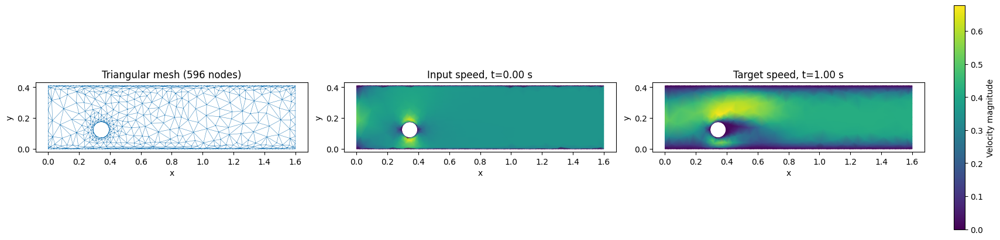

In [7]:
pos = example["mesh_pos"].numpy()
cells = example["cells"].numpy()

speed0 = torch.linalg.vector_norm(example["velocity_t"], dim=-1).numpy()
speed1 = torch.linalg.vector_norm(example["velocity_target"], dim=-1).numpy()

vmin = min(float(speed0.min()), float(speed1.min()))
vmax = max(float(speed0.max()), float(speed1.max()))

fig, axes = plt.subplots(1, 3, figsize=(17, 4), constrained_layout=True)

axes[0].triplot(pos[:, 0], pos[:, 1], cells, linewidth=0.35)
axes[0].set_title(f"Triangular mesh ({len(pos)} nodes)")

m0 = axes[1].tripcolor(
    pos[:, 0], pos[:, 1], cells, speed0,
    shading="gouraud", vmin=vmin, vmax=vmax,
)
axes[1].set_title(f"Input speed, t={example['time_s']:.2f} s")

m1 = axes[2].tripcolor(
    pos[:, 0], pos[:, 1], cells, speed1,
    shading="gouraud", vmin=vmin, vmax=vmax,
)
axes[2].set_title(f"Target speed, t={example['target_time_s']:.2f} s")

for ax in axes:
    ax.set_aspect("equal")
    ax.set_xlabel("x")
    ax.set_ylabel("y")

fig.colorbar(m1, ax=axes[1:], label="Velocity magnitude")
plt.show()

## 5. Prediction task

For every training example you are given the current state
$
\mathcal C_t=
\{\mathbf u_t,\;\text{mesh positions},\;\text{triangle connectivity},\;\text{node types}\}
$
and the target state one physical second later,
$
\mathbf u_{t+1\mathrm{s}}.
$
It is convenient to model the 1-second velocity increment
$
\Delta\mathbf u_t=
\mathbf u_{t+1\mathrm{s}}-\mathbf u_t.
$

### Deterministic model

You should construct a deterministic model that predicts one increment (or equivalently one future state) from the conditioning state. A standard deterministic baseline minimizes mean-squared error on the dynamic nodes.

### Conditional flow matching

You should construct a conditional flow-matching model for the distribution
$
p(\Delta\mathbf u_t\mid\mathcal C_t).
$
For conditional flow matching, a common training construction is:
$
\epsilon\sim\mathcal N(0,I),
\qquad
\tau\sim U[0,1],
$

$
z_\tau=(1-\tau)\epsilon+\tau\widetilde{\Delta\mathbf u}_t,
$

with target vector field

$
v^*=
\widetilde{\Delta\mathbf u}_t-\epsilon.
$

A sample is generated by integrating the learned ODE from $\tau=0$ to $1$, starting from fresh Gaussian noise.

Only **dynamic nodes** (`NORMAL` and `OUTFLOW`) should contribute to the prediction loss. During rollout, known inflow and wall values should remain fixed.

### What is not prescribed

You choose the model architecture, data normalization, feature representation, optimizer, learning-rate schedule, and the flow-matching sampler. Your design must support variable-size, nonuniform meshes.


## 6. Your model and training code

Implement your models and training procedure below.

Use only the **training split** for fitting model parameters and training statistics. Use the **validation split** for model selection. Do not tune on the test split.

For the final evaluation code later in this notebook, your implementation only needs to provide two small adapter functions that produce a **full next velocity field** after one 1-second model step. These adapter functions must return velocities in physical, unnormalized units.


In [8]:
# ============================================================
# TODO: your deterministic model, flow-matching model, training,
# validation, checkpointing, and inference utilities go here.
# imports and settings

import copy
from itertools import islice

import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Subset
from torch_geometric.data import Data
from torch_geometric.loader import DataLoader as GraphDataLoader

# Model (same for the deterministic and the flow-matching model)
HIDDEN_DIM = 128       
N_MP_LAYERS = 10        
TAU_DIM = 32            

# Training (same budget for both models)
BATCH_SIZE = 16
LIMIT_TRAIN_BATCHES = 600     
N_VAL_PAIRS = 500            
N_EPOCHS = 20
LEARNING_RATE = 1e-3
WEIGHT_DECAY = 1e-3
NUM_WORKERS = 0               

# Flow-matching sampler
FLOW_EULER_STEPS = 20
# ============================================================

c:\Users\Sujitha\anaconda3\envs\ml_clean\Lib\site-packages\torch\jit\_script.py:1491: FutureWarning: `torch.jit.script` is deprecated. Please switch to `torch.compile` or `torch.export`.
  warnings.warn(


In [9]:
NODE_TYPES = [NORMAL, INFLOW, OUTFLOW, WALL_BOUNDARY]


def cells_to_edge_index(cells):
    """Triangles (M, 3) -> directed edges (2, E): both directions, no duplicates."""
    edges = torch.cat([cells[:, [0, 1]], cells[:, [1, 2]], cells[:, [2, 0]]], dim=0)  # (3M, 2)
    edges = torch.cat([edges, edges.flip(1)], dim=0)                                  # add j -> i for every i -> j
    return torch.unique(edges, dim=0).T                                               # (2, E)


def mesh_edge_features(mesh_pos, edge_index):
    """Unit direction and length of every edge (same idea as edge_features in Practical 4)."""
    displacements = mesh_pos[edge_index[0]] - mesh_pos[edge_index[1]]
    unit_displacements = F.normalize(displacements, dim=-1)
    dists = torch.norm(displacements, dim=-1, keepdim=True).clamp(min=1e-6)
    return unit_displacements, dists


def node_type_one_hot(node_type):
    """(N,) integer labels -> (N, 4) one-hot: interior, inflow, outflow, wall."""
    return torch.stack([node_type == k for k in NODE_TYPES], dim=-1).float()


# Quick check on the example mesh
example_edge_index = cells_to_edge_index(example["cells"])
print("nodes:", example["mesh_pos"].shape[0], "| directed edges:", example_edge_index.shape[1])

nodes: 596 | directed edges: 3108


In [10]:
def compute_training_statistics(h5_path, horizon_steps):
    sums = {k: 0.0 for k in ["vel", "delta", "pos", "dist"]}
    squares = {k: 0.0 for k in sums}
    counts = {k: 0 for k in sums}

    def add(name, values):                      
        sums[name] = sums[name] + values.sum(axis=0)
        squares[name] = squares[name] + np.square(values).sum(axis=0)
        counts[name] += values.shape[0]

    with h5py.File(h5_path, "r") as f:
        for traj_id in tqdm(sorted(f["train"].keys()), desc="Training statistics"):
            g = f["train"][traj_id]
            vel = g["velocity"][:].astype(np.float64)                     # (T, N, 2)
            node_type = g["node_type"][:]
            dynamic = (node_type == NORMAL) | (node_type == OUTFLOW)
            delta = vel[horizon_steps:, dynamic] - vel[:-horizon_steps, dynamic]

            mesh_pos = torch.from_numpy(g["mesh_pos"][:]).float()
            cells = torch.from_numpy(g["cells"][:].astype(np.int64))
            _, dists = mesh_edge_features(mesh_pos, cells_to_edge_index(cells))

            add("vel", vel.reshape(-1, 2))
            add("delta", delta.reshape(-1, 2))
            add("pos", mesh_pos.numpy().astype(np.float64))
            add("dist", dists.numpy().astype(np.float64))

    stats = {}
    for name in sums:
        mean = sums[name] / counts[name]
        var = squares[name] / counts[name] - mean ** 2
        stats[f"{name}_mean"] = torch.tensor(mean, dtype=torch.float32)
        stats[f"{name}_std"] = torch.tensor(np.sqrt(np.maximum(var, 1e-12)), dtype=torch.float32)
    return stats


STATS = compute_training_statistics(DATA_PATH, HORIZON_STEPS)
for name, value in STATS.items():
    print(f"{name:11s}", value.numpy())

Training statistics:   0%|          | 0/500 [00:00<?, ?it/s]

vel_mean    [0.41813394 0.00060975]
vel_std     [0.55258673 0.12096894]
delta_mean  [-0.00742558  0.00012135]
delta_std   [0.1043108  0.06621691]
pos_mean    [0.72021127 0.20470372]
pos_std     [0.4747567  0.16222218]
dist_mean   [0.03708118]
dist_std    [0.02252895]


In [11]:
def build_graph(mesh_pos, cells, node_type, velocity, stats):
    """Mesh + current velocity"""
    s = {k: v.to(mesh_pos.device) for k, v in stats.items()}

    edge_index = cells_to_edge_index(cells)
    unit_displacements, dists = mesh_edge_features(mesh_pos, edge_index)
    edge_attr = torch.cat(
        [unit_displacements, (dists - s["dist_mean"]) / s["dist_std"]], dim=-1
    )                                                               

    x = torch.cat([
        (velocity - s["vel_mean"]) / s["vel_std"],                  # current velocity   (N, 2)
        (mesh_pos - s["pos_mean"]) / s["pos_std"],                  # where the node is  (N, 2)
        node_type_one_hot(node_type),                               # what the node is   (N, 4)
    ], dim=-1)                                                      
    return x, edge_index, edge_attr


class MeshGraphDataset(Dataset):

    def __init__(self, pair_dataset, stats):
        self.pair_dataset = pair_dataset
        self.stats = stats

    def __len__(self):
        return len(self.pair_dataset)

    def __getitem__(self, idx):
        item = self.pair_dataset[idx]
        x, edge_index, edge_attr = build_graph(
            item["mesh_pos"], item["cells"], item["node_type"], item["velocity_t"], self.stats
        )
        # normalized 1-second velocity increment
        y = (item["delta_velocity"] - self.stats["delta_mean"]) / self.stats["delta_std"]
        return Data(x=x, edge_index=edge_index, edge_attr=edge_attr, y=y,
                    dynamic_mask=item["dynamic_mask"])


NODE_DIM, EDGE_DIM, TARGET_DIM = 8, 3, 2

train_graphs = MeshGraphDataset(train_dataset, STATS)
valid_graphs = MeshGraphDataset(valid_dataset, STATS)

# every epoch is validated on the same data
val_indices = torch.randperm(
    len(valid_graphs), generator=torch.Generator().manual_seed(SEED)
)[:N_VAL_PAIRS].tolist()

train_loader = GraphDataLoader(train_graphs, batch_size=BATCH_SIZE, shuffle=True,
                               num_workers=NUM_WORKERS)
val_loader = GraphDataLoader(Subset(valid_graphs, val_indices), batch_size=BATCH_SIZE,
                             shuffle=False, num_workers=NUM_WORKERS)

batch = next(iter(train_loader))
print(batch)
print("graphs in batch:", batch.num_graphs, "| total nodes:", batch.num_nodes)

DataBatch(x=[9497, 8], edge_index=[2, 49486], edge_attr=[49486, 3], y=[9497, 2], dynamic_mask=[9497], batch=[9497], ptr=[17])
graphs in batch: 16 | total nodes: 9497


In [12]:
class NeuralMessagePassingLayer(nn.Module):
    """Message-passing layer"""

    def __init__(self, in_features, in_edge_features, hidden_dim, out_features):
        super().__init__()
        self.message_mlp = nn.Sequential(
            nn.Linear(2 * in_features + in_edge_features, hidden_dim),
            nn.SiLU(),
            nn.Linear(hidden_dim, hidden_dim),
        )
        self.node_mlp = nn.Sequential(
            nn.Linear(in_features + hidden_dim, hidden_dim),
            nn.SiLU(),
            nn.Linear(hidden_dim, out_features),
        )

    def forward(self, x, edge_index, edge_attr):
        source_nodes, target_nodes = edge_index
        messages = self.message_mlp(
            torch.cat([x[source_nodes], x[target_nodes], edge_attr], dim=-1)
        )
        # average all incoming messages per target node
        aggregated_messages = torch.zeros(x.size(0), messages.size(-1), device=x.device)
        aggregated_messages.index_reduce_(0, target_nodes, messages, reduce="mean",
                                          include_self=False)
        return self.node_mlp(torch.cat([x, aggregated_messages], dim=-1))


def timestep_embedding(timesteps, dim, max_period=10000):
    """Sinusoidal embedding of the flow time"""
    half = dim // 2
    freqs = torch.exp(
        -math.log(max_period) * torch.arange(half, device=timesteps.device, dtype=torch.float32) / half
    )
    args = timesteps[:, None].float() * freqs[None]
    embedding = torch.cat([args.cos(), args.sin()], dim=-1)
    if dim % 2:
        embedding = F.pad(embedding, (0, 1))
    return embedding


class MeshGNN(nn.Module):
    """Encoder MLP -> residual message passing -> decoder MLP"""

    def __init__(self, node_dim, edge_dim, hidden_dim, output_dim, n_layers):
        super().__init__()
        self.encoder = nn.Sequential(
            nn.Linear(node_dim, hidden_dim), nn.SiLU(),
            nn.Linear(hidden_dim, hidden_dim), nn.SiLU(),
        )
        self.mp_layers = nn.ModuleList([
            NeuralMessagePassingLayer(hidden_dim, edge_dim, hidden_dim, hidden_dim)
            for _ in range(n_layers)
        ])
        self.decoder = nn.Sequential(
            nn.Linear(hidden_dim, hidden_dim), nn.SiLU(), nn.Linear(hidden_dim, output_dim)
        )

    def forward(self, x, edge_index, edge_attr):
        h = self.encoder(x)
        for layer in self.mp_layers:
            h_new = layer(h, edge_index, edge_attr)
            h = h + F.silu(h_new)                      # residual connection
            h = F.layer_norm(h, (h.size(-1),))
        return self.decoder(h)


class DenoisingMeshGNN(nn.Module):

    def __init__(self, target_dim, tau_dim, cond_dim, edge_dim, hidden_dim, n_layers):
        super().__init__()
        self.tau_dim = tau_dim
        self.gnn = MeshGNN(target_dim + cond_dim + tau_dim, edge_dim, hidden_dim, target_dim, n_layers)

    def forward(self, x_tau, tau, cond, edge_index, edge_attr):

        tau_emb = timestep_embedding(tau * 1000, self.tau_dim)
        return self.gnn(torch.cat([x_tau, cond, tau_emb], dim=-1), edge_index, edge_attr)


det_model = MeshGNN(NODE_DIM, EDGE_DIM, HIDDEN_DIM, TARGET_DIM, N_MP_LAYERS).to(DEVICE)
flow_model = DenoisingMeshGNN(TARGET_DIM, TAU_DIM, NODE_DIM, EDGE_DIM, HIDDEN_DIM, N_MP_LAYERS).to(DEVICE)

print("Deterministic parameters:", sum(p.numel() for p in det_model.parameters()))
print("Flow-matching parameters:", sum(p.numel() for p in flow_model.parameters()))

Deterministic parameters: 1026434
Flow-matching parameters: 1030786


In [13]:
def deterministic_loss(model, batch, generator=None):
    """MSE on the normalized increment"""
    pred = model(batch.x, batch.edge_index, batch.edge_attr)
    return F.mse_loss(pred[batch.dynamic_mask], batch.y[batch.dynamic_mask])


def flow_matching_loss(model, batch, generator=None):
    """Conditional flow matching"""
    mask = batch.dynamic_mask.unsqueeze(-1).float()                         
    x_1 = batch.y * mask                                                     
    x_0 = torch.randn(x_1.shape, device=x_1.device, generator=generator) * mask   

    tau = torch.rand(batch.num_graphs, device=x_1.device, generator=generator)    
    tau = tau[batch.batch]                                                   

    x_tau = (1 - tau[:, None]) * x_0 + tau[:, None] * x_1
    u = x_1 - x_0

    v = model(x_tau, tau, batch.x, batch.edge_index, batch.edge_attr)
    return F.mse_loss(v[batch.dynamic_mask], u[batch.dynamic_mask])


def run_epoch(model, loader, loss_fn, optimizer=None, max_batches=None, seed=1234):
    training = optimizer is not None
    model.train(training)
    
    rng = None if training else torch.Generator(device=DEVICE).manual_seed(seed)
    total, count = 0.0, 0
    with torch.set_grad_enabled(training):
        for batch in islice(loader, max_batches):
            batch = batch.to(DEVICE)
            loss = loss_fn(model, batch, rng)
            if not torch.isfinite(loss):
                raise RuntimeError("Non-finite loss.")
            if training:
                optimizer.zero_grad(set_to_none=True)
                loss.backward()
                optimizer.step()
            total += loss.item() * batch.num_graphs
            count += batch.num_graphs
    return total / count


def train_model(model, loss_fn, checkpoint_path, n_epochs=N_EPOCHS):
    optimizer = torch.optim.AdamW(model.parameters(), lr=LEARNING_RATE, weight_decay=WEIGHT_DECAY)
    scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=n_epochs)
    history = {"train": [], "validation": []}
    best_loss, best_state = float("inf"), None

    for epoch in range(1, n_epochs + 1):
        train_loss = run_epoch(model, train_loader, loss_fn, optimizer, LIMIT_TRAIN_BATCHES)
        val_loss = run_epoch(model, val_loader, loss_fn)
        history["train"].append(train_loss)
        history["validation"].append(val_loss)

        if val_loss < best_loss:                       # model selection on the validation split
            best_loss = val_loss
            best_state = {k: v.detach().cpu().clone() for k, v in model.state_dict().items()}
            torch.save({"model": best_state, "stats": STATS}, checkpoint_path)

        scheduler.step()
        print(f"Epoch {epoch:02d}/{n_epochs}: train={train_loss:.6f}, validation={val_loss:.6f}")

    model.load_state_dict(best_state)
    model.eval()
    print(f"Best validation loss: {best_loss:.6f} (saved to {checkpoint_path})")
    return history


def plot_loss_curves(history, title):
    plt.figure(figsize=(7, 4))
    for label, losses in history.items():
        plt.plot(np.arange(1, len(losses) + 1), losses, label=label)
    plt.xlabel("Epoch")
    plt.ylabel("Loss (normalized units)")
    plt.yscale("log")
    plt.title(title)
    plt.legend()
    plt.grid(alpha=0.3)
    plt.show()

Epoch 01/20: train=0.788066, validation=1.181800
Epoch 02/20: train=0.589939, validation=1.097367
Epoch 03/20: train=0.502758, validation=1.193866
Epoch 04/20: train=0.460020, validation=0.961902
Epoch 05/20: train=0.434725, validation=1.092094
Epoch 06/20: train=0.413358, validation=1.084641
Epoch 07/20: train=0.395124, validation=1.020933
Epoch 08/20: train=0.360181, validation=1.040620
Epoch 09/20: train=0.325924, validation=0.933818
Epoch 10/20: train=0.285469, validation=0.973453
Epoch 11/20: train=0.256118, validation=0.846760
Epoch 12/20: train=0.223082, validation=0.766231
Epoch 13/20: train=0.192509, validation=0.791294
Epoch 14/20: train=0.169236, validation=0.785478
Epoch 15/20: train=0.151142, validation=0.768153
Epoch 16/20: train=0.136791, validation=0.733217
Epoch 17/20: train=0.127180, validation=0.756809
Epoch 18/20: train=0.122470, validation=0.734115
Epoch 19/20: train=0.115015, validation=0.733884
Epoch 20/20: train=0.117551, validation=0.728511
Best validation loss

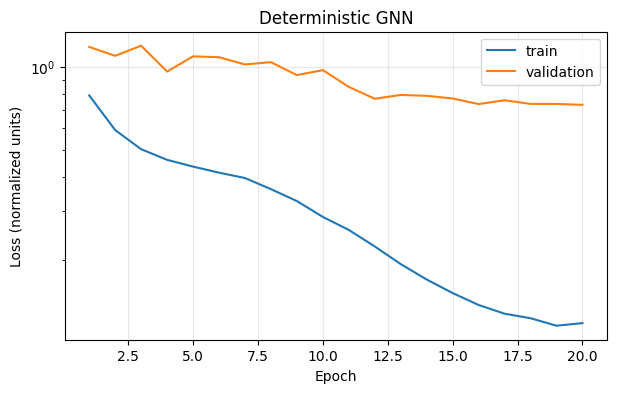

In [14]:
det_history = train_model(det_model, deterministic_loss, "det_model.pt")
plot_loss_curves(det_history, "Deterministic GNN")

Epoch 01/20: train=0.732366, validation=0.778712
Epoch 02/20: train=0.484053, validation=0.658784
Epoch 03/20: train=0.423861, validation=0.538139
Epoch 04/20: train=0.360840, validation=0.526563
Epoch 05/20: train=0.312741, validation=0.456497
Epoch 06/20: train=0.290446, validation=0.427148
Epoch 07/20: train=0.278406, validation=0.381536
Epoch 08/20: train=0.240709, validation=0.363460
Epoch 09/20: train=0.234284, validation=0.345932
Epoch 10/20: train=0.231033, validation=0.352120
Epoch 11/20: train=0.212751, validation=0.318226
Epoch 12/20: train=0.208806, validation=0.314371
Epoch 13/20: train=0.197602, validation=0.318918
Epoch 14/20: train=0.185841, validation=0.308884
Epoch 15/20: train=0.181784, validation=0.295191
Epoch 16/20: train=0.170060, validation=0.269981
Epoch 17/20: train=0.169295, validation=0.270105
Epoch 18/20: train=0.162733, validation=0.278517
Epoch 19/20: train=0.158428, validation=0.262122
Epoch 20/20: train=0.159318, validation=0.262933
Best validation loss

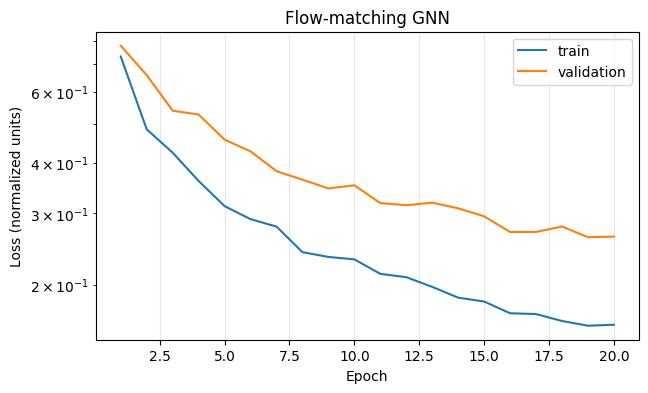

In [15]:
flow_history = train_model(flow_model, flow_matching_loss, "flow_model.pt")
plot_loss_curves(flow_history, "Flow-matching GNN")

In [ ]:
# det_model.load_state_dict(torch.load("det_model.pt")["model"])
# flow_model.load_state_dict(torch.load("flow_model.pt")["model"])
# det_model.eval()
# flow_model.eval()

DenoisingMeshGNN(
  (gnn): MeshGNN(
    (encoder): Sequential(
      (0): Linear(in_features=42, out_features=128, bias=True)
      (1): SiLU()
      (2): Linear(in_features=128, out_features=128, bias=True)
      (3): SiLU()
    )
    (mp_layers): ModuleList(
      (0-9): 10 x NeuralMessagePassingLayer(
        (message_mlp): Sequential(
          (0): Linear(in_features=259, out_features=128, bias=True)
          (1): SiLU()
          (2): Linear(in_features=128, out_features=128, bias=True)
        )
        (node_mlp): Sequential(
          (0): Linear(in_features=256, out_features=128, bias=True)
          (1): SiLU()
          (2): Linear(in_features=128, out_features=128, bias=True)
        )
      )
    )
    (decoder): Sequential(
      (0): Linear(in_features=128, out_features=128, bias=True)
      (1): SiLU()
      (2): Linear(in_features=128, out_features=2, bias=True)
    )
  )
)

# 7. Final evaluation: wake temporal activity

The supplied evaluation code computes how strongly the velocity field changes over a finite time interval in a fixed downstream wake region. The following sections explain the metric and protocol implemented below. **Your task is to connect your trained models through the two adapter functions, run the provided evaluation and plotting functions, and interpret the results alongside rollout visualizations**.

For two states at times $t_0$ and $t_1$, define at each mesh node $i$,
$
a_i(t_0,t_1)=
\frac{
\left\|
\mathbf u_i(t_1)-\mathbf u_i(t_0)
\right\|_2
}{
t_1-t_0
}.
$

This uses the full velocity vector, so changes in both velocity magnitude and direction contribute.

For a triangle $K$ with nodes $i,j,k$, the nodal scalar $a$ is linearly interpolated over the triangle. Its triangle-average value is therefore
$
a_K=
\frac{a_i+a_j+a_k}{3}.
$

For all triangles whose centroids lie inside the fixed wake region, define the area-weighted temporal activity
$
D_{\mathrm{wake}}(t_0,t_1)=
\frac{
\sum_{K\in\mathrm{wake}} A_K\,a_K
}{
\sum_{K\in\mathrm{wake}} A_K
}.
$

### Interpretation

A larger value means that the wake velocity field changes more strongly between the two endpoint states. A smaller value means less finite-time change.

The first rollout interval $0\rightarrow1\,\mathrm{s}$ is treated as a burn-in interval and is not used to calculate the metric. The reported metric begins with the interval $1\rightarrow2\,\mathrm{s}$.


## 8. Wake region used by the metric

The provided metric function uses a fixed physical rectangle downstream of the cylinder:

$
0.55\le x\le1.55,
\qquad
0.03\le y\le0.39.
$

A triangle contributes if its centroid lies inside this rectangle. The same region is used for ground truth, the deterministic model, and every generative sample.

The area weighting is important because the mesh is nonuniform: a large triangle represents more physical area than a small triangle.

The region is fixed in advance and must not be tuned separately for different models.


In [16]:
# ============================================================
# Fixed wake region and absolute temporal-activity metric
# ============================================================

METRIC_WAKE_X_MIN = 0.55
METRIC_WAKE_X_MAX = 1.55
METRIC_WAKE_Y_MIN = 0.03
METRIC_WAKE_Y_MAX = 0.39


def triangle_areas_and_centroids(mesh_pos, cells):
    if torch.is_tensor(mesh_pos):
        mesh_pos = mesh_pos.detach().cpu().numpy()

    if torch.is_tensor(cells):
        cells = cells.detach().cpu().numpy()

    pos = np.asarray(mesh_pos, dtype=np.float64)
    cells = np.asarray(cells, dtype=np.int64)

    p0 = pos[cells[:, 0]]
    p1 = pos[cells[:, 1]]
    p2 = pos[cells[:, 2]]

    cross = (
        (p1[:, 0] - p0[:, 0])
        *
        (p2[:, 1] - p0[:, 1])
        -
        (p1[:, 1] - p0[:, 1])
        *
        (p2[:, 0] - p0[:, 0])
    )

    areas = 0.5 * np.abs(cross)
    centroids = (p0 + p1 + p2) / 3.0

    return areas, centroids


def wake_triangle_mask(centroids):
    x = centroids[:, 0]
    y = centroids[:, 1]

    return (
        (x >= METRIC_WAKE_X_MIN)
        &
        (x <= METRIC_WAKE_X_MAX)
        &
        (y >= METRIC_WAKE_Y_MIN)
        &
        (y <= METRIC_WAKE_Y_MAX)
    )


def wake_velocity_temporal_activity(
    mesh_pos,
    cells,
    velocity_start,
    velocity_end,
    delta_t,
):
    """
    Area-weighted wake average of

        ||u(t1) - u(t0)||_2 / (t1 - t0)

    using the full velocity vector.
    """

    if delta_t <= 0:
        raise ValueError("delta_t must be positive.")

    if torch.is_tensor(velocity_start):
        velocity_start = velocity_start.detach().cpu().numpy()

    if torch.is_tensor(velocity_end):
        velocity_end = velocity_end.detach().cpu().numpy()

    cells_np = (
        cells.detach().cpu().numpy()
        if torch.is_tensor(cells)
        else np.asarray(cells)
    ).astype(np.int64)

    v0 = np.asarray(velocity_start, dtype=np.float64)
    v1 = np.asarray(velocity_end, dtype=np.float64)

    # Full-vector finite-time change rate at each node.
    node_activity = (
        np.linalg.norm(
            v1 - v0,
            axis=-1,
        )
        /
        float(delta_t)
    )

    areas, centroids = triangle_areas_and_centroids(
        mesh_pos,
        cells_np,
    )

    wake = wake_triangle_mask(centroids)

    if not np.any(wake):
        raise RuntimeError(
            "No mesh triangles fall inside the fixed wake region."
        )

    # Exact triangle mean of the linearly interpolated nodal scalar.
    tri_activity = (
        node_activity[cells_np[:, 0]]
        +
        node_activity[cells_np[:, 1]]
        +
        node_activity[cells_np[:, 2]]
    ) / 3.0

    return float(
        np.sum(
            areas[wake]
            *
            tri_activity[wake]
        )
        /
        np.sum(areas[wake])
    )


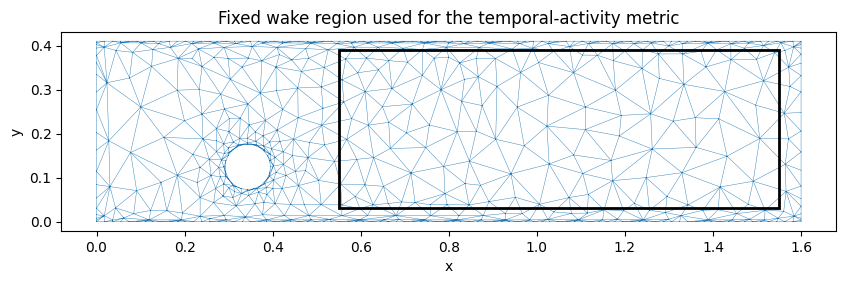

In [17]:
# Visualize the fixed evaluation region on the example mesh.
from matplotlib.patches import Rectangle

example_pos = example["mesh_pos"].numpy()
example_cells = example["cells"].numpy()

fig, ax = plt.subplots(figsize=(10, 3.2))
ax.triplot(example_pos[:, 0], example_pos[:, 1], example_cells, linewidth=0.3)

rect = Rectangle(
    (METRIC_WAKE_X_MIN, METRIC_WAKE_Y_MIN),
    METRIC_WAKE_X_MAX - METRIC_WAKE_X_MIN,
    METRIC_WAKE_Y_MAX - METRIC_WAKE_Y_MIN,
    fill=False,
    linewidth=2,
)
ax.add_patch(rect)
ax.set_title("Fixed wake region used for the temporal-activity metric")
ax.set_xlabel("x")
ax.set_ylabel("y")
ax.set_aspect("equal")
plt.show()

## 10. Rollout evaluation protocol

The provided evaluation code implements the following protocol for the final comparison. Run it after implementing the two model adapter functions below:

- The evaluator uses **20 held-out test trajectories**;
- Every rollout starts from the same ground-truth state at $t=0$;
- Each model step advances the model by **1 second**;
- The rollout code generates model states at nominal times $t=0,1,2,3,4,5,6\,\mathrm{s}$;
- The evaluator automatically excludes $0\rightarrow1\,\mathrm{s}$ from the metric as burn-in; students do not need to implement this exclusion;
- The evaluator calculates the metric on the intervals
  $
  1\rightarrow2,\quad
  2\rightarrow3,\quad
  3\rightarrow4,\quad
  4\rightarrow5,\quad
  5\rightarrow6\,\mathrm{s};
  $
- The evaluator runs **5 flow-matching rollouts per test trajectory** with distinct random seeds by repeatedly calling your `generative_next_velocity` adapter. You must implement the conditional sampling procedure, including noise generation using the supplied random generator and numerical integration of the learned flow-matching ODE;
- The evaluator computes the absolute temporal-activity value separately for every generative rollout;
- The supplied aggregation function averages the 5 generative activity values within each trajectory/interval first, then summarizes across trajectories.

### Final ground-truth endpoint

The stored trajectory ends at $5.99\,\mathrm{s}$, not exactly $6.00\,\mathrm{s}$. Therefore, for the final displayed interval:

- deterministic and flow-matching rollouts use their nominal $5.00\rightarrow6.00\,\mathrm{s}$ states and divide by $1.00\,\mathrm{s}$;
- ground truth uses the available $5.00\rightarrow5.99\,\mathrm{s}$ states and divides by the actual $0.99\,\mathrm{s}$.

The final GT point is therefore a $0.99\,\mathrm{s}$ reference for the nominal 6-second endpoint.

This metric measures **finite-time temporal activity**, not pointwise prediction accuracy and not the spatial location or phase of individual vortices. Use it together with rollout visualizations.


In [18]:
def load_full_trajectory(h5_path, split, traj_id):
    """Load one full trajectory into CPU torch tensors."""
    with h5py.File(h5_path, "r") as f:
        g = f[split][traj_id]
        return {
            "trajectory_id": traj_id,
            "mesh_pos": torch.from_numpy(g["mesh_pos"][:]).float(),
            "cells": torch.from_numpy(g["cells"][:].astype(np.int64)).long(),
            "node_type": torch.from_numpy(g["node_type"][:].astype(np.int64)).long(),
            "velocity": torch.from_numpy(g["velocity"][:]).float(),
        }


def test_trajectory_ids(h5_path):
    with h5py.File(h5_path, "r") as f:
        return sorted(f["test"].keys())

### Connect your trained models to the evaluator

Implement the two adapter functions below to connect your trained models to the supplied evaluator. The deterministic adapter must call your trained predictor. The generative adapter must implement or call your flow-matching sampler, including Gaussian noise generation and numerical integration of the learned ODE; this sampling code is not supplied. The metric, boundary enforcement, autoregressive rollout loops, evaluation protocol, aggregation, and metric plotting are already implemented in the following code cells.

Each function must return the **full physical velocity field one second later**, with shape `(N, 2)`. If your model works with normalized velocities or normalized increments internally, perform the required denormalization inside the adapter before returning.

The evaluation code does not assume any particular neural-network architecture.

`generative_next_velocity` should produce a new conditional sample when the supplied random generator changes. After implementing both adapters, run the example calls provided at the ends of the evaluation and aggregation cells with your trained models to compute, summarize, and plot the results. Interpret the comparison using the metric definition and rollout visualizations.


In [19]:
@torch.no_grad()
def deterministic_next_velocity(model, trajectory, current_velocity):
    """
    TODO: predict the full velocity field one physical second ahead.

    Parameters
    ----------
    model : trained model
        Your model, placed on DEVICE and set to evaluation mode before rollout.
    trajectory : dict[str, torch.Tensor]
        Static mesh information for one trajectory (no batch dimension):
        - mesh_pos: float32 tensor, shape (N, 2), containing node (x, y) coordinates.
        - cells: int64 tensor, shape (M, 3), containing triangle node indices.
        - node_type: int64 tensor, shape (N,), containing labels 0 (interior),
          4 (inflow), 5 (outflow), or 6 (wall).
        All tensors are on DEVICE. N is the number of nodes and M is the number
        of triangles; both can vary between trajectories. This dictionary does
        not contain velocity history or future ground-truth states.
    current_velocity : torch.Tensor
        Float32 tensor of shape (N, 2) on DEVICE, in physical, unnormalized
        units. Columns contain (u_x, u_y). This is the ground-truth initial
        state for the first step and the previous prediction for later steps.

    Returns
    -------
    torch.Tensor
        Full velocity field u(t + 1 s), shape (N, 2), on the same device and
        with the same dtype as current_velocity, in physical, unnormalized
        units. If the model predicts a normalized increment, denormalize it
        and add it to current_velocity before returning.

    Notes
    -----
    One call advances physical time by 1 second (100 stored data steps).
    Return values for all N nodes. The supplied rollout code restores the
    known inflow and wall velocities after each call; interior and outflow
    velocities remain predicted.
    Implement model-specific feature preparation, normalization, inference,
    and denormalization here. This adapter returns one deterministic prediction.
    """
    mesh_pos = trajectory["mesh_pos"]
    cells = trajectory["cells"]
    node_type = trajectory["node_type"]

    x, edge_index, edge_attr = build_graph(mesh_pos, cells, node_type, current_velocity, STATS)

    predicted_increment = model(x, edge_index, edge_attr)

    delta_mean = STATS["delta_mean"].to(current_velocity.device)
    delta_std = STATS["delta_std"].to(current_velocity.device)
    increment = predicted_increment * delta_std + delta_mean

    next_velocity = current_velocity + increment
    return next_velocity.to(current_velocity.dtype)


@torch.no_grad()
def generative_next_velocity(model, trajectory, current_velocity, generator):
    """
    TODO: sample a full velocity field one physical second ahead.

    Parameters
    ----------
    model : trained model
        Your model, placed on DEVICE and set to evaluation mode before rollout.
    trajectory : dict[str, torch.Tensor]
        Static mesh information for one trajectory (no batch dimension):
        - mesh_pos: float32 tensor, shape (N, 2), containing node (x, y) coordinates.
        - cells: int64 tensor, shape (M, 3), containing triangle node indices.
        - node_type: int64 tensor, shape (N,), containing labels 0 (interior),
          4 (inflow), 5 (outflow), or 6 (wall).
        All tensors are on DEVICE. N is the number of nodes and M is the number
        of triangles; both can vary between trajectories. This dictionary does
        not contain velocity history or future ground-truth states.
    current_velocity : torch.Tensor
        Float32 tensor of shape (N, 2) on DEVICE, in physical, unnormalized
        units. Columns contain (u_x, u_y). This is the ground-truth initial
        state for the first step and the previous prediction for later steps.
    generator : torch.Generator
        Random generator on DEVICE, seeded by the supplied rollout code.
        Use it for all sampling randomness, for example:
        torch.randn(current_velocity.shape, device=current_velocity.device,
                    dtype=current_velocity.dtype, generator=generator).
        Do not reset its seed inside this function. Its state advances across
        rollout steps, and separate rollouts receive distinct seeds.

    Returns
    -------
    torch.Tensor
        Full velocity field u(t + 1 s), shape (N, 2), on the same device and
        with the same dtype as current_velocity, in physical, unnormalized
        units. If the model predicts a normalized increment, denormalize it
        and add it to current_velocity before returning.

    Notes
    -----
    One call advances physical time by 1 second (100 stored data steps).
    Return values for all N nodes. The supplied rollout code restores the
    known inflow and wall velocities after each call; interior and outflow
    velocities remain predicted.
    Implement or call your conditional flow-matching sampler here: draw fresh
    Gaussian noise, integrate the learned vector field over flow time tau from
    0 to 1 conditioned on current_velocity and the mesh, and convert the sample
    to a physical velocity field. Flow time tau is separate from physical time.
    Noise generation and ODE integration are student tasks, not supplied by
    the evaluator. Return one sample per call, not an ensemble or sample mean.
    """
    mesh_pos = trajectory["mesh_pos"]
    cells = trajectory["cells"]
    node_type = trajectory["node_type"]
    device = current_velocity.device

    cond, edge_index, edge_attr = build_graph(mesh_pos, cells, node_type, current_velocity, STATS)

    dynamic = dynamic_node_mask(node_type)
    mask = dynamic.unsqueeze(-1).float()

    x = torch.randn(current_velocity.shape, device=device, generator=generator)
    x = x * mask

    n_steps = FLOW_EULER_STEPS
    dt = 1.0 / n_steps
    n_nodes = current_velocity.shape[0]

    for step in range(n_steps):
        tau_value = step * dt
        tau = torch.full((n_nodes,), tau_value, device=device)

        velocity_field = model(x, tau, cond, edge_index, edge_attr)
        x = x + dt * velocity_field
        x = x * mask

    delta_mean = STATS["delta_mean"].to(device)
    delta_std = STATS["delta_std"].to(device)
    increment = x * delta_std + delta_mean

    next_velocity = current_velocity + increment
    return next_velocity.to(current_velocity.dtype)

In [20]:
def enforce_known_boundaries(next_velocity, current_velocity, node_type):
    """Keep inflow/wall nodes fixed; interior and outflow nodes remain predicted."""
    out = next_velocity.clone()
    dynamic = dynamic_node_mask(node_type)
    out[~dynamic] = current_velocity[~dynamic]
    return out


@torch.no_grad()
def rollout_deterministic_generic(model, trajectory, n_steps=5):
    current = trajectory["velocity"][0].to(DEVICE)
    tr_static = {
        "mesh_pos": trajectory["mesh_pos"].to(DEVICE),
        "cells": trajectory["cells"].to(DEVICE),
        "node_type": trajectory["node_type"].to(DEVICE),
    }

    states = [current.detach().cpu()]
    for _ in range(n_steps):
        nxt = deterministic_next_velocity(model, tr_static, current)
        nxt = enforce_known_boundaries(nxt, current, tr_static["node_type"])
        current = nxt
        states.append(current.detach().cpu())

    return torch.stack(states)


@torch.no_grad()
def rollout_generative_generic(model, trajectory, n_steps=5, seed=0):
    current = trajectory["velocity"][0].to(DEVICE)
    tr_static = {
        "mesh_pos": trajectory["mesh_pos"].to(DEVICE),
        "cells": trajectory["cells"].to(DEVICE),
        "node_type": trajectory["node_type"].to(DEVICE),
    }

    gen = torch.Generator(device=DEVICE)
    gen.manual_seed(int(seed))

    states = [current.detach().cpu()]
    for _ in range(n_steps):
        nxt = generative_next_velocity(model, tr_static, current, gen)
        nxt = enforce_known_boundaries(nxt, current, tr_static["node_type"])
        current = nxt
        states.append(current.detach().cpu())

    return torch.stack(states)

In [21]:
# ============================================================
# Final rollout temporal-activity evaluation
# ============================================================

N_EVAL_TRAJ = 20
N_GENERATIVE_SAMPLES = 5

# Six 1-second model steps are needed to form the final scored
# interval 5 -> 6 s.
N_MODEL_ROLLOUT_STEPS = 6

# The first interval 0 -> 1 s is burn-in.
BURN_IN_STEPS = 1

EVAL_SEED = 1234


@torch.no_grad()
def evaluate_rollout_temporal_activity(
    det_model,
    generative_model,
):
    rows = []

    ids = test_trajectory_ids(DATA_PATH)[:N_EVAL_TRAJ]

    for traj_number, traj_id in enumerate(
        tqdm(
            ids,
            desc="Test trajectories",
        )
    ):
        tr = load_full_trajectory(
            DATA_PATH,
            "test",
            traj_id,
        )

        # ----------------------------------------------------
        # Generate model rollouts to nominal t = 6 s.
        # ----------------------------------------------------

        det = rollout_deterministic_generic(
            det_model,
            tr,
            n_steps=N_MODEL_ROLLOUT_STEPS,
        )

        fm_rollouts = []

        for sample_id in tqdm(
            range(N_GENERATIVE_SAMPLES),
            desc=f"Generative samples {traj_id}",
            leave=False,
        ):
            seed = (
                EVAL_SEED
                +
                1000 * traj_number
                +
                sample_id
            )

            fm_rollouts.append(
                rollout_generative_generic(
                    generative_model,
                    tr,
                    n_steps=N_MODEL_ROLLOUT_STEPS,
                    seed=seed,
                )
            )

        # ----------------------------------------------------
        # Score intervals:
        #
        #   1 -> 2
        #   2 -> 3
        #   3 -> 4
        #   4 -> 5
        #   5 -> 6 nominally
        #
        # 0 -> 1 is burn-in and is not scored.
        # ----------------------------------------------------

        T = tr["velocity"].shape[0]

        for end_step in range(
            BURN_IN_STEPS + 1,
            N_MODEL_ROLLOUT_STEPS + 1,
        ):
            start_step = end_step - 1

            nominal_start_s = (
                start_step
                *
                PREDICTION_DT
            )

            nominal_end_s = (
                end_step
                *
                PREDICTION_DT
            )

            # ------------------------------------------------
            # Ground-truth endpoints.
            #
            # For 1->2, ..., 4->5, exact 1-second endpoints
            # exist in the stored trajectory.
            #
            # For the final nominal 5->6 interval, use
            # 5.00 -> 5.99 s.
            # ------------------------------------------------

            gt_start_idx = (
                start_step
                *
                HORIZON_STEPS
            )

            desired_gt_end_idx = (
                end_step
                *
                HORIZON_STEPS
            )

            gt_end_idx = min(
                desired_gt_end_idx,
                T - 1,
            )

            gt_start_time_s = (
                gt_start_idx
                *
                DT
            )

            gt_end_time_s = (
                gt_end_idx
                *
                DT
            )

            gt_delta_t = (
                gt_end_time_s
                -
                gt_start_time_s
            )

            if gt_delta_t <= 0:
                continue

            gt_activity = (
                wake_velocity_temporal_activity(
                    tr["mesh_pos"],
                    tr["cells"],
                    tr["velocity"][gt_start_idx],
                    tr["velocity"][gt_end_idx],
                    gt_delta_t,
                )
            )

            rows.append({
                "trajectory": traj_id,
                "interval_start_s": nominal_start_s,
                "interval_end_s": nominal_end_s,
                "gt_interval_end_s": gt_end_time_s,
                "model": "Ground truth",
                "sample": -1,
                "temporal_activity": gt_activity,
            })

            # ------------------------------------------------
            # Deterministic model:
            # always a nominal 1-second model interval.
            # ------------------------------------------------

            det_activity = (
                wake_velocity_temporal_activity(
                    tr["mesh_pos"],
                    tr["cells"],
                    det[start_step],
                    det[end_step],
                    PREDICTION_DT,
                )
            )

            rows.append({
                "trajectory": traj_id,
                "interval_start_s": nominal_start_s,
                "interval_end_s": nominal_end_s,
                "gt_interval_end_s": gt_end_time_s,
                "model": "Deterministic",
                "sample": -1,
                "temporal_activity": det_activity,
            })

            # ------------------------------------------------
            # Flow matching: evaluate every sampled rollout.
            # ------------------------------------------------

            for sample_id, fm in enumerate(
                fm_rollouts
            ):
                fm_activity = (
                    wake_velocity_temporal_activity(
                        tr["mesh_pos"],
                        tr["cells"],
                        fm[start_step],
                        fm[end_step],
                        PREDICTION_DT,
                    )
                )

                rows.append({
                    "trajectory": traj_id,
                    "interval_start_s": nominal_start_s,
                    "interval_end_s": nominal_end_s,
                    "gt_interval_end_s": gt_end_time_s,
                    "model": "Flow matching",
                    "sample": sample_id,
                    "temporal_activity": fm_activity,
                })

    return pd.DataFrame(rows)


# Run after implementing the two model adapter functions above:

rollout_activity_raw = evaluate_rollout_temporal_activity(
    det_model,
    flow_model,
)


Test trajectories:   0%|          | 0/20 [00:00<?, ?it/s]

Generative samples traj_0000:   0%|          | 0/5 [00:00<?, ?it/s]

Generative samples traj_0001:   0%|          | 0/5 [00:00<?, ?it/s]

Generative samples traj_0002:   0%|          | 0/5 [00:00<?, ?it/s]

Generative samples traj_0003:   0%|          | 0/5 [00:00<?, ?it/s]

...

Generative samples traj_0015:   0%|          | 0/5 [00:00<?, ?it/s]

Generative samples traj_0016:   0%|          | 0/5 [00:00<?, ?it/s]

Generative samples traj_0017:   0%|          | 0/5 [00:00<?, ?it/s]

Generative samples traj_0018:   0%|          | 0/5 [00:00<?, ?it/s]

Generative samples traj_0019:   0%|          | 0/5 [00:00<?, ?it/s]

,model,interval_start_s,interval_end_s,mean_activity,std_activity,median_activity,n_trajectories
0,Deterministic,1.0,2.0,0.063111,0.022025,0.060914,20
1,Deterministic,2.0,3.0,0.028106,0.022806,0.026947,20
2,Deterministic,3.0,4.0,0.028011,0.032673,0.012160,20
3,Deterministic,4.0,5.0,0.029237,0.038804,0.007919,20
4,Deterministic,5.0,6.0,0.031871,0.043452,0.008138,20
5,Flow matching,1.0,2.0,0.085343,0.032675,0.090174,20
6,Flow matching,2.0,3.0,0.053107,0.038078,0.039505,20
7,Flow matching,3.0,4.0,0.045879,0.042126,0.033487,20
8,Flow matching,4.0,5.0,0.044400,0.042217,0.027045,20
9,Flow matching,5.0,6.0,0.042745,0.041512,0.031293,20


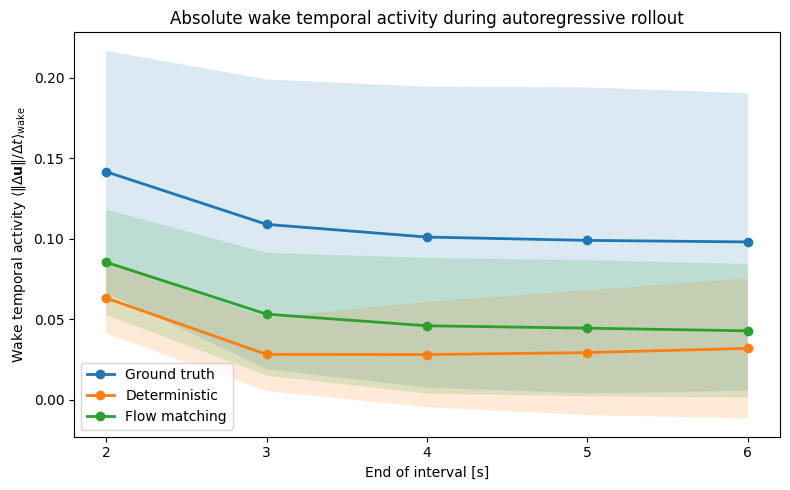

In [22]:
# ============================================================
# Aggregate correctly and plot the metric
# ============================================================

def summarize_rollout_temporal_activity(
    rollout_activity_raw,
):
    # --------------------------------------------------------
    # First average independent FM samples within the same
    # trajectory and interval.
    #
    # GT and deterministic each already have one value.
    # --------------------------------------------------------

    per_condition = (
        rollout_activity_raw
        .groupby(
            [
                "model",
                "trajectory",
                "interval_start_s",
                "interval_end_s",
            ]
        )["temporal_activity"]
        .mean()
        .reset_index()
    )

    # --------------------------------------------------------
    # Then summarize across independent test trajectories.
    # --------------------------------------------------------

    by_time = (
        per_condition
        .groupby(
            [
                "model",
                "interval_start_s",
                "interval_end_s",
            ]
        )
        .agg(
            mean_activity=(
                "temporal_activity",
                "mean",
            ),
            std_activity=(
                "temporal_activity",
                "std",
            ),
            median_activity=(
                "temporal_activity",
                "median",
            ),
            n_trajectories=(
                "trajectory",
                "nunique",
            ),
        )
        .reset_index()
    )

    return (
        per_condition,
        by_time,
    )


def plot_rollout_temporal_activity(
    by_time,
    show_std=True,
):
    plt.figure(
        figsize=(8, 5)
    )

    for model_name in [
        "Ground truth",
        "Deterministic",
        "Flow matching",
    ]:
        d = (
            by_time[
                by_time["model"]
                ==
                model_name
            ]
            .sort_values(
                "interval_end_s"
            )
        )

        plt.plot(
            d["interval_end_s"],
            d["mean_activity"],
            marker="o",
            linewidth=2,
            label=model_name,
        )

        if show_std:
            plt.fill_between(
                d["interval_end_s"],
                d["mean_activity"]
                -
                d["std_activity"],
                d["mean_activity"]
                +
                d["std_activity"],
                alpha=0.16,
            )

    plt.xlabel(
        "End of interval [s]"
    )

    plt.ylabel(
        r"Wake temporal activity "
        r"$\langle \|\Delta\mathbf{u}\|/\Delta t\rangle_{\mathrm{wake}}$"
    )

    plt.title(
        "Absolute wake temporal activity during autoregressive rollout"
    )

    plt.xticks(
        [2, 3, 4, 5, 6]
    )

    plt.legend()
    plt.tight_layout()
    plt.show()


# Example after evaluation:

per_condition, by_time = summarize_rollout_temporal_activity(
    rollout_activity_raw
)

display(by_time)
plot_rollout_temporal_activity(by_time)


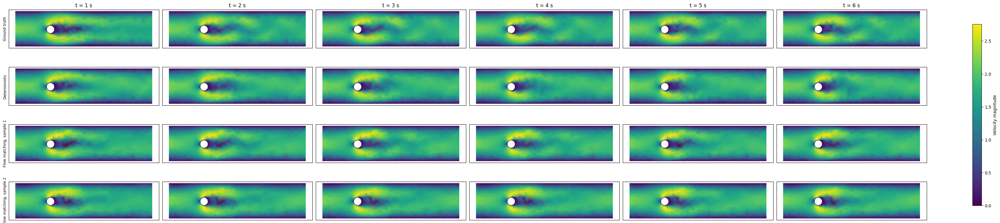

In [23]:
# Compare the ground truth, deterministic and flow matching rollouts at different time steps

VIS_TRAJECTORY = 0           
VIS_FLOW_SAMPLES = 2        
SHOW_TIMES = [1, 2, 3, 4, 5,6]      

vis_traj = load_full_trajectory(DATA_PATH, "test", test_trajectory_ids(DATA_PATH)[VIS_TRAJECTORY])
vis_det = rollout_deterministic_generic(det_model, vis_traj, n_steps=N_MODEL_ROLLOUT_STEPS)
vis_flow = [
    rollout_generative_generic(flow_model, vis_traj, n_steps=N_MODEL_ROLLOUT_STEPS, seed=s)
    for s in range(VIS_FLOW_SAMPLES)
]


n_states = vis_traj["velocity"].shape[0]
vis_gt = torch.stack([
    vis_traj["velocity"][min(k * HORIZON_STEPS, n_states - 1)]
    for k in range(N_MODEL_ROLLOUT_STEPS + 1)
])

rows = [("Ground truth", vis_gt), ("Deterministic", vis_det)]
rows += [(f"Flow matching, sample {s + 1}", r) for s, r in enumerate(vis_flow)]

vis_pos = vis_traj["mesh_pos"].numpy()
vis_cells = vis_traj["cells"].numpy()
vis_vmax = float(torch.linalg.vector_norm(vis_gt, dim=-1).max())

fig, axes = plt.subplots(len(rows), len(SHOW_TIMES),
                         figsize=(5.5 * len(SHOW_TIMES), 1.9 * len(rows)),
                         constrained_layout=True, squeeze=False)
for r, (name, states) in enumerate(rows):
    for c, t in enumerate(SHOW_TIMES):
        speed = torch.linalg.vector_norm(states[t], dim=-1).numpy()
        im = axes[r, c].tripcolor(vis_pos[:, 0], vis_pos[:, 1], vis_cells, speed,
                                  shading="gouraud", vmin=0.0, vmax=vis_vmax)
        axes[r, c].set_aspect("equal")
        axes[r, c].set_xticks([])
        axes[r, c].set_yticks([])
        if r == 0:
            axes[r, c].set_title(f"t = {t} s")
    axes[r, 0].set_ylabel(name, fontsize=9)
fig.colorbar(im, ax=axes, label="Velocity magnitude", shrink=0.8)
fig.savefig("rollouts.png", dpi=200, bbox_inches="tight")
plt.show()

Ground truth wake activity:  0.1104
Deterministic wake activity: 0.0375
 euler_steps  mean_wake_activity  std_wake_activity  ms_per_1s_model_step
           1            0.013867           0.003048              6.867041
           2            0.017662           0.007067             13.525783
           5            0.031096           0.020483             27.203425
          10            0.042502           0.031453             52.456213
          20            0.052302           0.039769            116.891179
          50            0.057521           0.044393            471.413231


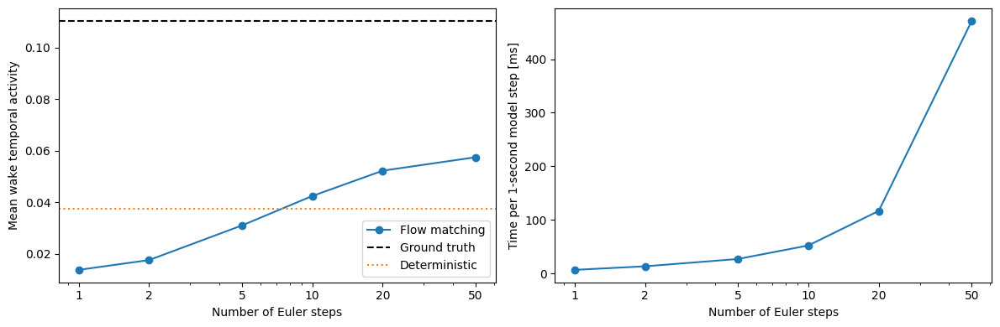

In [24]:
# Effect of the number of Euler integration steps on sampling
import time

STEP_COUNTS = [1, 2, 5, 10, 20, 50]
N_TRAJ_STEPS = 10
N_SAMPLES_STEPS = 3

step_trajs = [load_full_trajectory(DATA_PATH, "test", tid)
              for tid in test_trajectory_ids(DATA_PATH)[:N_TRAJ_STEPS]]


def mean_wake_activity(tr, states, last_dt=PREDICTION_DT):
    """Average wake activity over the scored intervals 1->2, ..., 5->6."""
    values = []
    for k in range(BURN_IN_STEPS, N_MODEL_ROLLOUT_STEPS):
        dt = last_dt if k == N_MODEL_ROLLOUT_STEPS - 1 else PREDICTION_DT
        values.append(wake_velocity_temporal_activity(
            tr["mesh_pos"], tr["cells"], states[k], states[k + 1], dt))
    return float(np.mean(values))


# Ground truth and deterministic model as reference
gt_vals, det_vals = [], []
for tr in step_trajs:
    T = tr["velocity"].shape[0]
    gt_states = torch.stack([tr["velocity"][min(k * HORIZON_STEPS, T - 1)]
                             for k in range(N_MODEL_ROLLOUT_STEPS + 1)])
    gt_vals.append(mean_wake_activity(tr, gt_states, last_dt=(T - 1 - 5 * HORIZON_STEPS) * DT))
    det_vals.append(mean_wake_activity(tr, rollout_deterministic_generic(det_model, tr, N_MODEL_ROLLOUT_STEPS)))

# Flow matching with different numbers of Euler steps
original_steps = FLOW_EULER_STEPS
step_rows = []
for n_steps in STEP_COUNTS:
    FLOW_EULER_STEPS = n_steps
    activities = []
    if DEVICE.type == "cuda":
        torch.cuda.synchronize()
    start = time.perf_counter()
    for i, tr in enumerate(step_trajs):
        for s in range(N_SAMPLES_STEPS):
            states = rollout_generative_generic(flow_model, tr, N_MODEL_ROLLOUT_STEPS,
                                                seed=EVAL_SEED + 1000 * i + s)
            activities.append(mean_wake_activity(tr, states))
    if DEVICE.type == "cuda":
        torch.cuda.synchronize()
    elapsed = time.perf_counter() - start
    step_rows.append({
        "euler_steps": n_steps,
        "mean_wake_activity": np.mean(activities),
        "std_wake_activity": np.std(activities),
        "ms_per_1s_model_step": 1000 * elapsed / (len(step_trajs) * N_SAMPLES_STEPS * N_MODEL_ROLLOUT_STEPS),
    })
FLOW_EULER_STEPS = original_steps

step_results = pd.DataFrame(step_rows)
print(f"Ground truth wake activity:  {np.mean(gt_vals):.4f}")
print(f"Deterministic wake activity: {np.mean(det_vals):.4f}")
print(step_results.to_string(index=False))

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(STEP_COUNTS, step_results["mean_wake_activity"], marker="o", label="Flow matching")
axes[0].axhline(np.mean(gt_vals), color="k", ls="--", label="Ground truth")
axes[0].axhline(np.mean(det_vals), color="tab:orange", ls=":", label="Deterministic")
axes[0].set_ylabel("Mean wake temporal activity")
axes[0].legend()
axes[1].plot(STEP_COUNTS, step_results["ms_per_1s_model_step"], marker="o")
axes[1].set_ylabel("Time per 1-second model step [ms]")
for ax in axes:
    ax.set_xscale("log")
    ax.set_xticks(STEP_COUNTS)
    ax.set_xticklabels(STEP_COUNTS)
    ax.set_xlabel("Number of Euler steps")
plt.tight_layout()
plt.show()

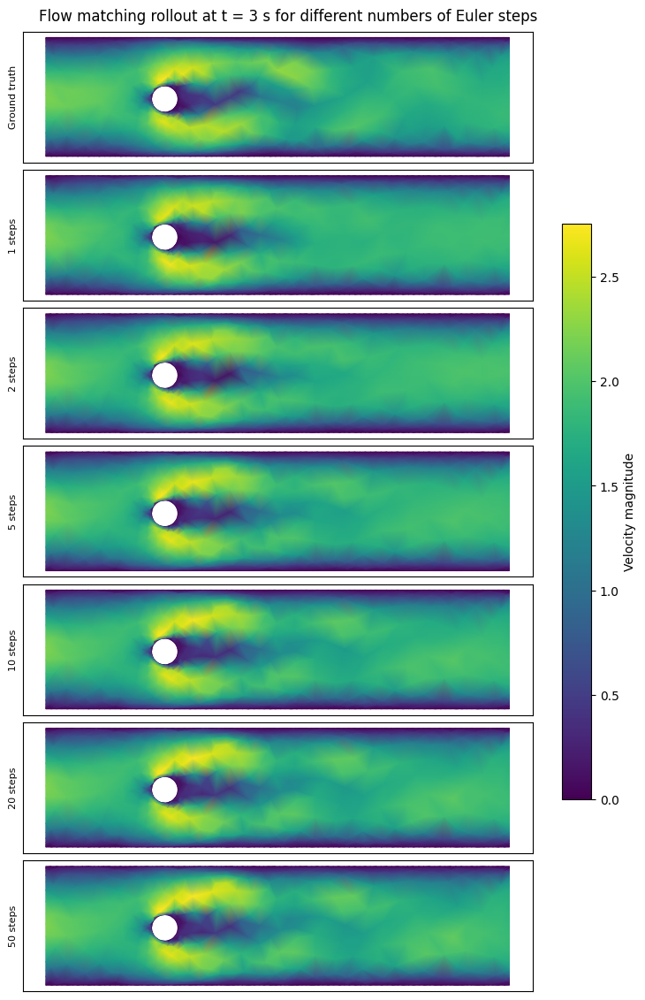

In [25]:
# One rollout per number of Euler steps
VIS_T = 3
vis_tr = step_trajs[0]
vis_pos, vis_cells = vis_tr["mesh_pos"].numpy(), vis_tr["cells"].numpy()
gt_speed = torch.linalg.vector_norm(vis_tr["velocity"][VIS_T * HORIZON_STEPS], dim=-1).numpy()

fig, axes = plt.subplots(len(STEP_COUNTS) + 1, 1, figsize=(8, 1.6 * (len(STEP_COUNTS) + 1)),
                         constrained_layout=True)
speeds = [("Ground truth", gt_speed)]
for n_steps in STEP_COUNTS:
    FLOW_EULER_STEPS = n_steps
    states = rollout_generative_generic(flow_model, vis_tr, VIS_T, seed=0)
    speeds.append((f"{n_steps} steps", torch.linalg.vector_norm(states[VIS_T], dim=-1).numpy()))
FLOW_EULER_STEPS = original_steps

for ax, (name, speed) in zip(axes, speeds):
    im = ax.tripcolor(vis_pos[:, 0], vis_pos[:, 1], vis_cells, speed,
                      shading="gouraud", vmin=0, vmax=float(gt_speed.max()))
    ax.set_ylabel(name, fontsize=8)
    ax.set_aspect("equal")
    ax.set_xticks([])
    ax.set_yticks([])
fig.colorbar(im, ax=axes, label="Velocity magnitude", shrink=0.6)
fig.suptitle(f"Flow matching rollout at t = {VIS_T} s for different numbers of Euler steps")
plt.show()

Saved: ['deterministic_rollout_traj_0000.gif', 'deterministic_rollout_traj_0005.gif', 'deterministic_rollout_traj_0010.gif', 'flow_matching_rollout_traj_0000.gif', 'flow_matching_rollout_traj_0005.gif', 'flow_matching_rollout_traj_0010.gif']
Zipped into deterministic_rollout_gifs.zip and flow_matching_rollout_gifs.zip


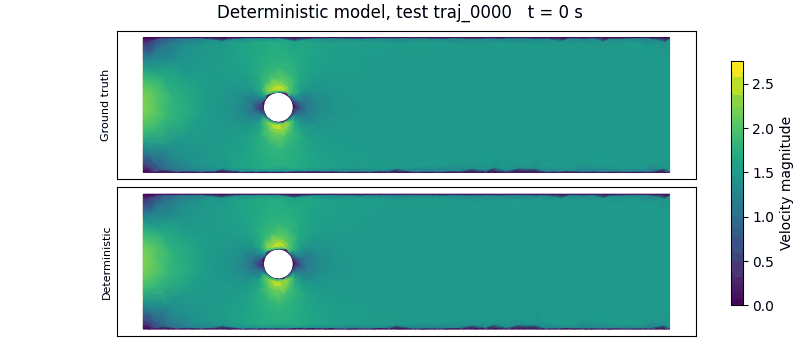

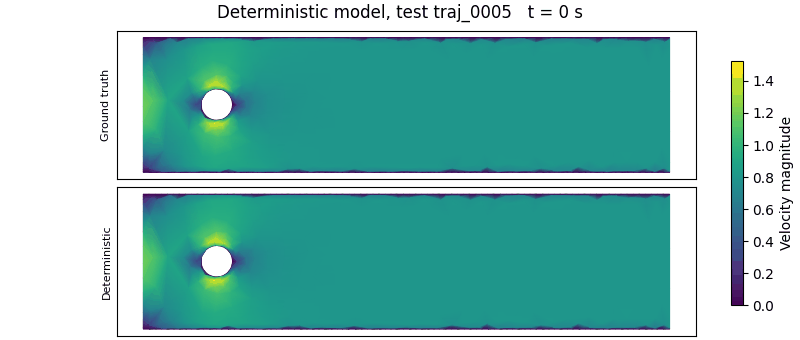

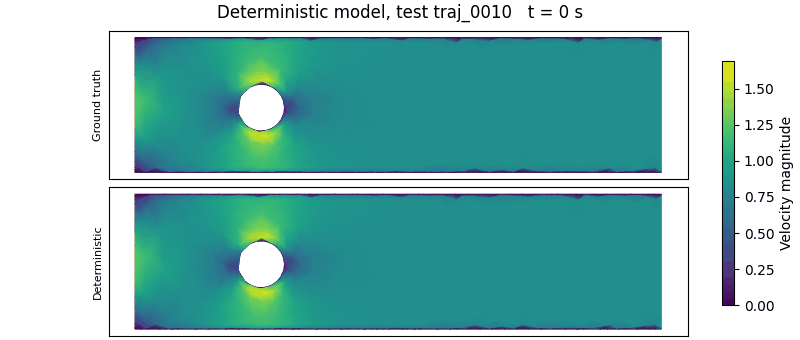

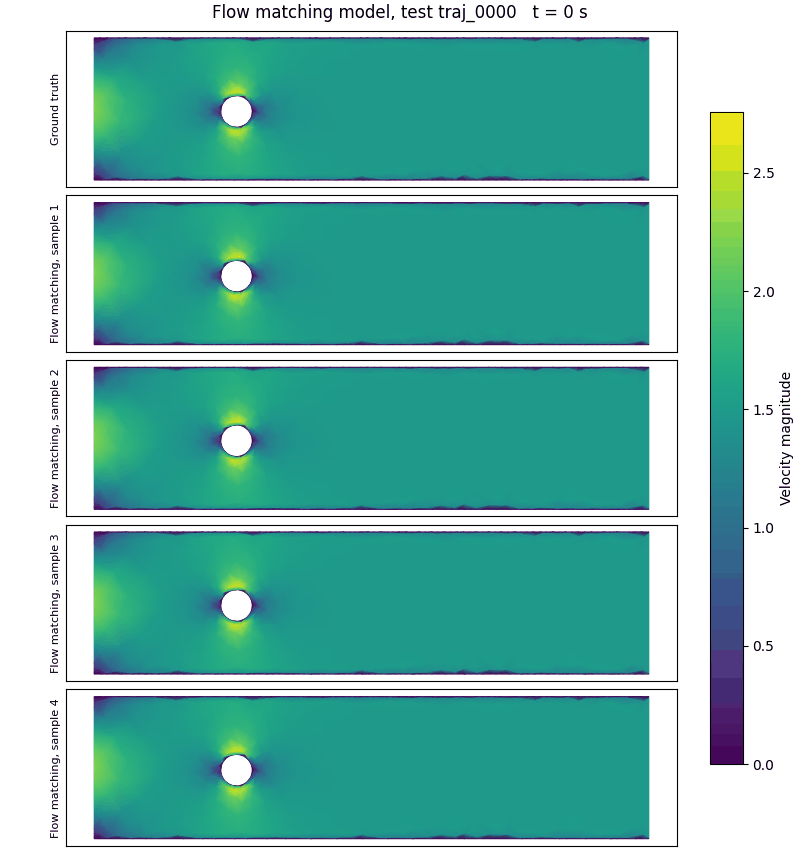

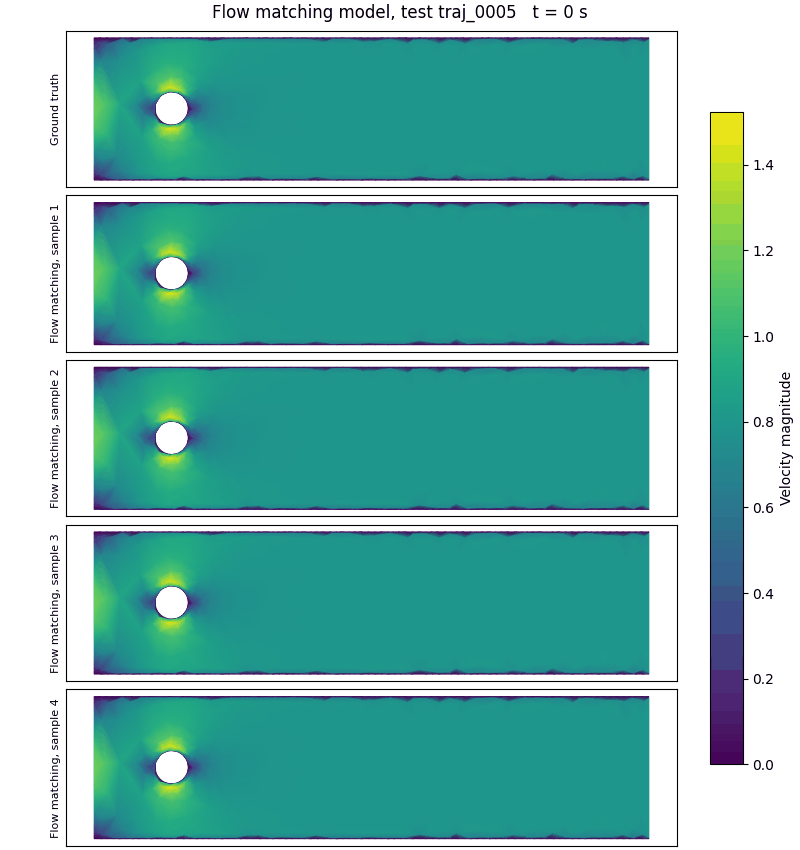

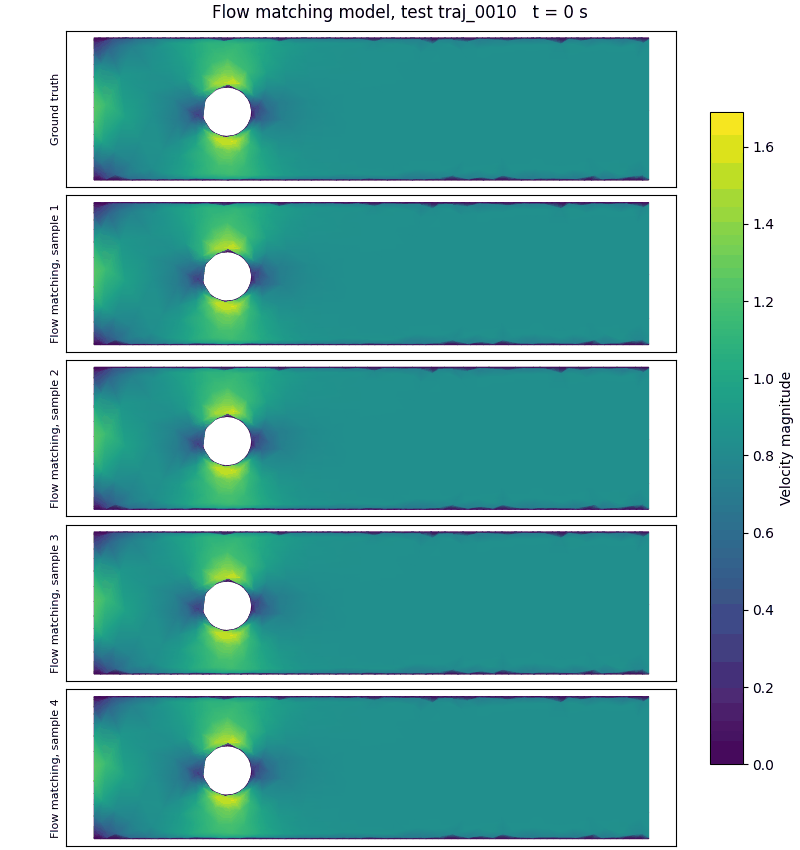

In [26]:
# Rollout GIFs for the deterministic and the flow matching model
import zipfile
from matplotlib.animation import FuncAnimation, PillowWriter
from matplotlib.colors import Normalize
from IPython.display import Image, display

GIF_TRAJ_INDICES = [0, 5, 10] 
N_GIF_FLOW_SAMPLES = 4
GIF_FPS = 1 


def gt_states_at_model_times(tr):
    """Ground truth at t = 0, 1, ..., 6 s (the last stored state is 5.99 s)."""
    T = tr["velocity"].shape[0]
    return torch.stack([tr["velocity"][min(k * HORIZON_STEPS, T - 1)]
                        for k in range(N_MODEL_ROLLOUT_STEPS + 1)])


def save_rollout_gif(tr, rows, path, title):
    """rows: list of (name, states) with states of shape (n_frames, N, 2)."""
    pos, cells = tr["mesh_pos"].numpy(), tr["cells"].numpy()
    speeds = [(name, torch.linalg.vector_norm(states, dim=-1).numpy()) for name, states in rows]
    vmax = float(speeds[0][1].max()) 

    fig, axes = plt.subplots(len(rows), 1, figsize=(8, 1.7 * len(rows)),
                             constrained_layout=True, squeeze=False)
    axes = axes[:, 0]
    fig.colorbar(plt.cm.ScalarMappable(norm=Normalize(0, vmax), cmap="viridis"),
                 ax=axes, label="Velocity magnitude", shrink=0.8)

    def draw(k):
        for ax, (name, speed) in zip(axes, speeds):
            ax.clear()
            ax.tripcolor(pos[:, 0], pos[:, 1], cells, speed[k],
                         shading="gouraud", vmin=0, vmax=vmax, cmap="viridis")
            ax.set_aspect("equal")
            ax.set_xticks([])
            ax.set_yticks([])
            ax.set_ylabel(name, fontsize=8)
        fig.suptitle(f"{title}   t = {k} s")

    anim = FuncAnimation(fig, draw, frames=speeds[0][1].shape[0])
    anim.save(path, writer=PillowWriter(fps=GIF_FPS))
    plt.close(fig)


all_test_ids = test_trajectory_ids(DATA_PATH)
det_gifs, flow_gifs = [], []

for idx in GIF_TRAJ_INDICES:
    traj_id = all_test_ids[idx]
    tr = load_full_trajectory(DATA_PATH, "test", traj_id)
    gt = gt_states_at_model_times(tr)

    det = rollout_deterministic_generic(det_model, tr, n_steps=N_MODEL_ROLLOUT_STEPS)
    det_path = f"deterministic_rollout_{traj_id}.gif"
    save_rollout_gif(tr, [("Ground truth", gt), ("Deterministic", det)],
                     det_path, f"Deterministic model, test {traj_id}")
    det_gifs.append(det_path)

    flow_rows = [("Ground truth", gt)]
    for s in range(N_GIF_FLOW_SAMPLES):
        sample = rollout_generative_generic(flow_model, tr, n_steps=N_MODEL_ROLLOUT_STEPS,
                                            seed=EVAL_SEED + 1000 * idx + s)
        flow_rows.append((f"Flow matching, sample {s + 1}", sample))
    flow_path = f"flow_matching_rollout_{traj_id}.gif"
    save_rollout_gif(tr, flow_rows, flow_path, f"Flow matching model, test {traj_id}")
    flow_gifs.append(flow_path)

with zipfile.ZipFile("deterministic_rollout_gifs.zip", "w") as z:
    for path in det_gifs:
        z.write(path)
with zipfile.ZipFile("flow_matching_rollout_gifs.zip", "w") as z:
    for path in flow_gifs:
        z.write(path)

print("Saved:", det_gifs + flow_gifs)
print("Zipped into deterministic_rollout_gifs.zip and flow_matching_rollout_gifs.zip")

for path in det_gifs + flow_gifs:
    display(Image(filename=path))